LangGraph is a framework built by the LangChain team that lets you design AI workflows as a flowchart (graph) instead of a straight line.

Real AI agents need loops and decisions: An agent often has to try a tool, check if the answer is good enough, loop back to try again if something failed, or pause and ask a human before continuing. LangGraph makes those loops and decision branches easy to build and control.

components of langraph-
edge
node
state

we can either use 
1.Graph API 
2.Functional API

to make a youtube video to a blog we need to make few steps like
start-> transctipt->title-> final
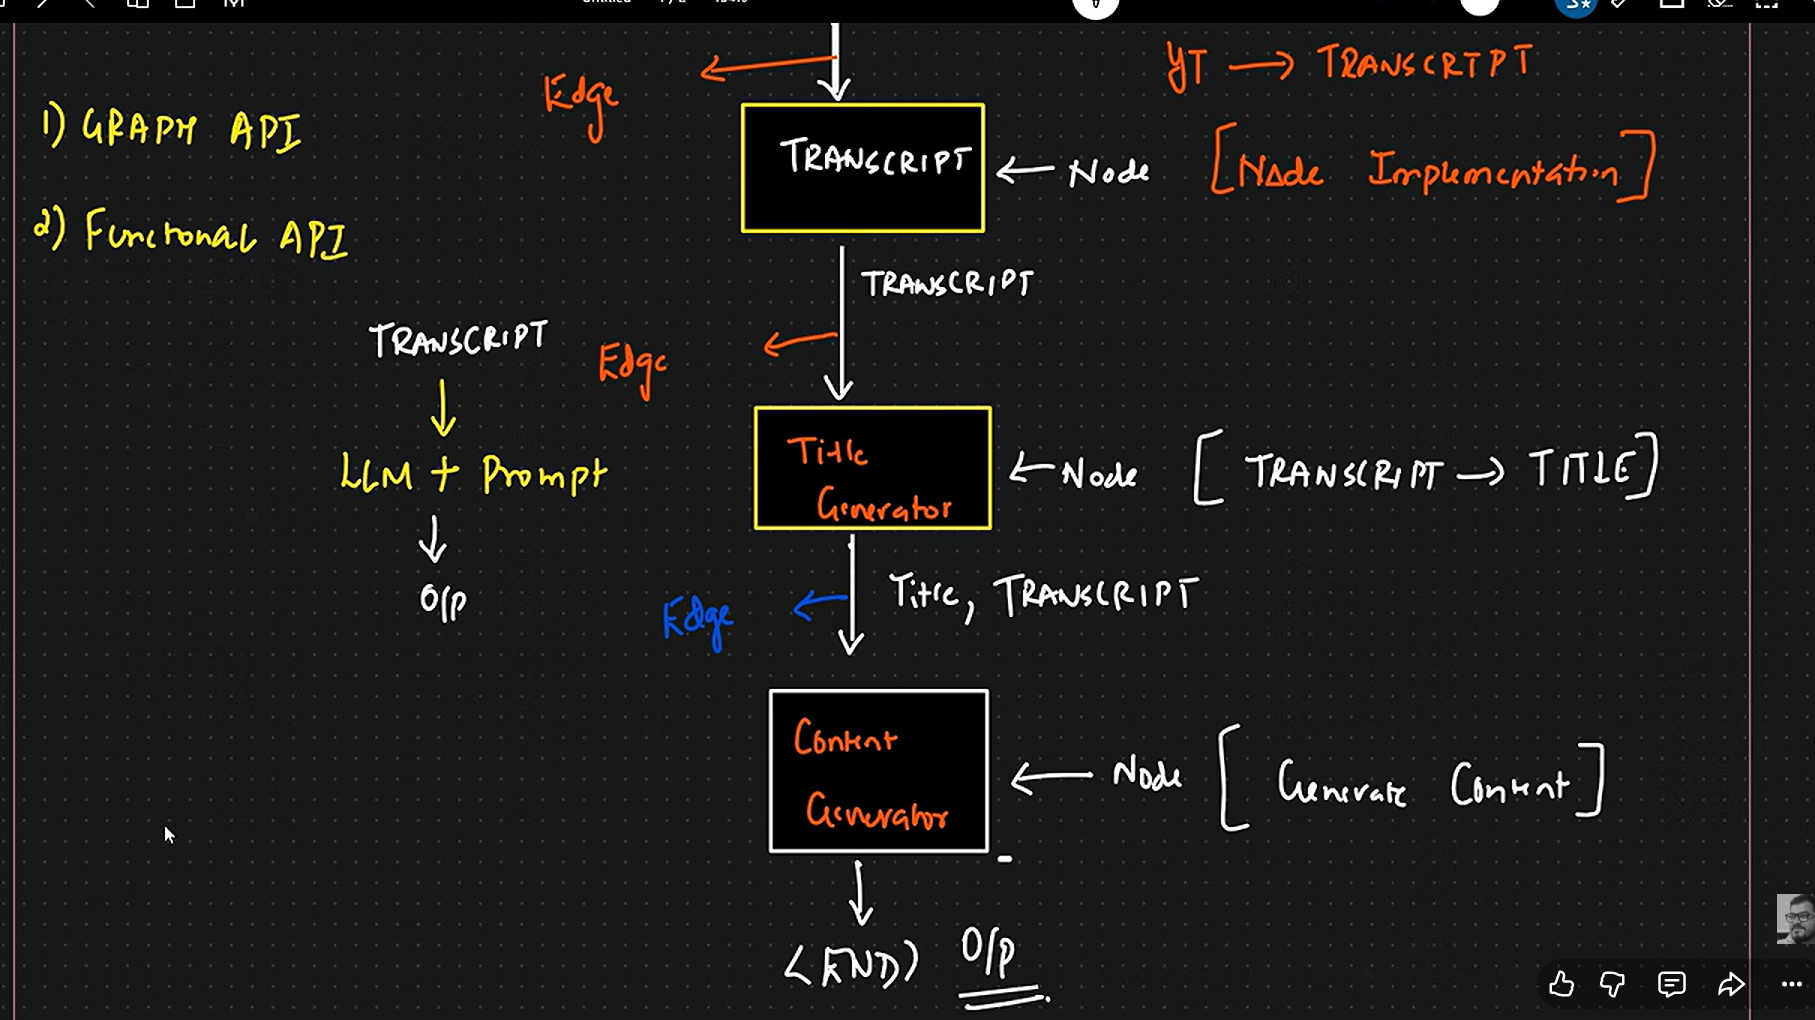 

Real-World Example: Customer Support Email Bot

Imagine building a support bot that reads a customer's email, decides if it is a Refund or a General Question, and writes the right reply:

LangGraph's job (The Flowchart):
Hold the shared dictionary (State: email, category, reply).

Run Node 1 (classify the email).Use an if/else Edge:if category == "refund" $\rightarrow$ jump to Node 2A (refund_node).else $\rightarrow$ jump to Node 2B (general_node).

LangChain's job (Inside the Nodes):

Inside Node 1, you use LangChain's init_chat_model + with_structured_output to ask Gemini to classify the email.

Inside Node 2A / 2B, you use LangChain's ChatPromptTemplate + model.invoke() to generate the actual reply.

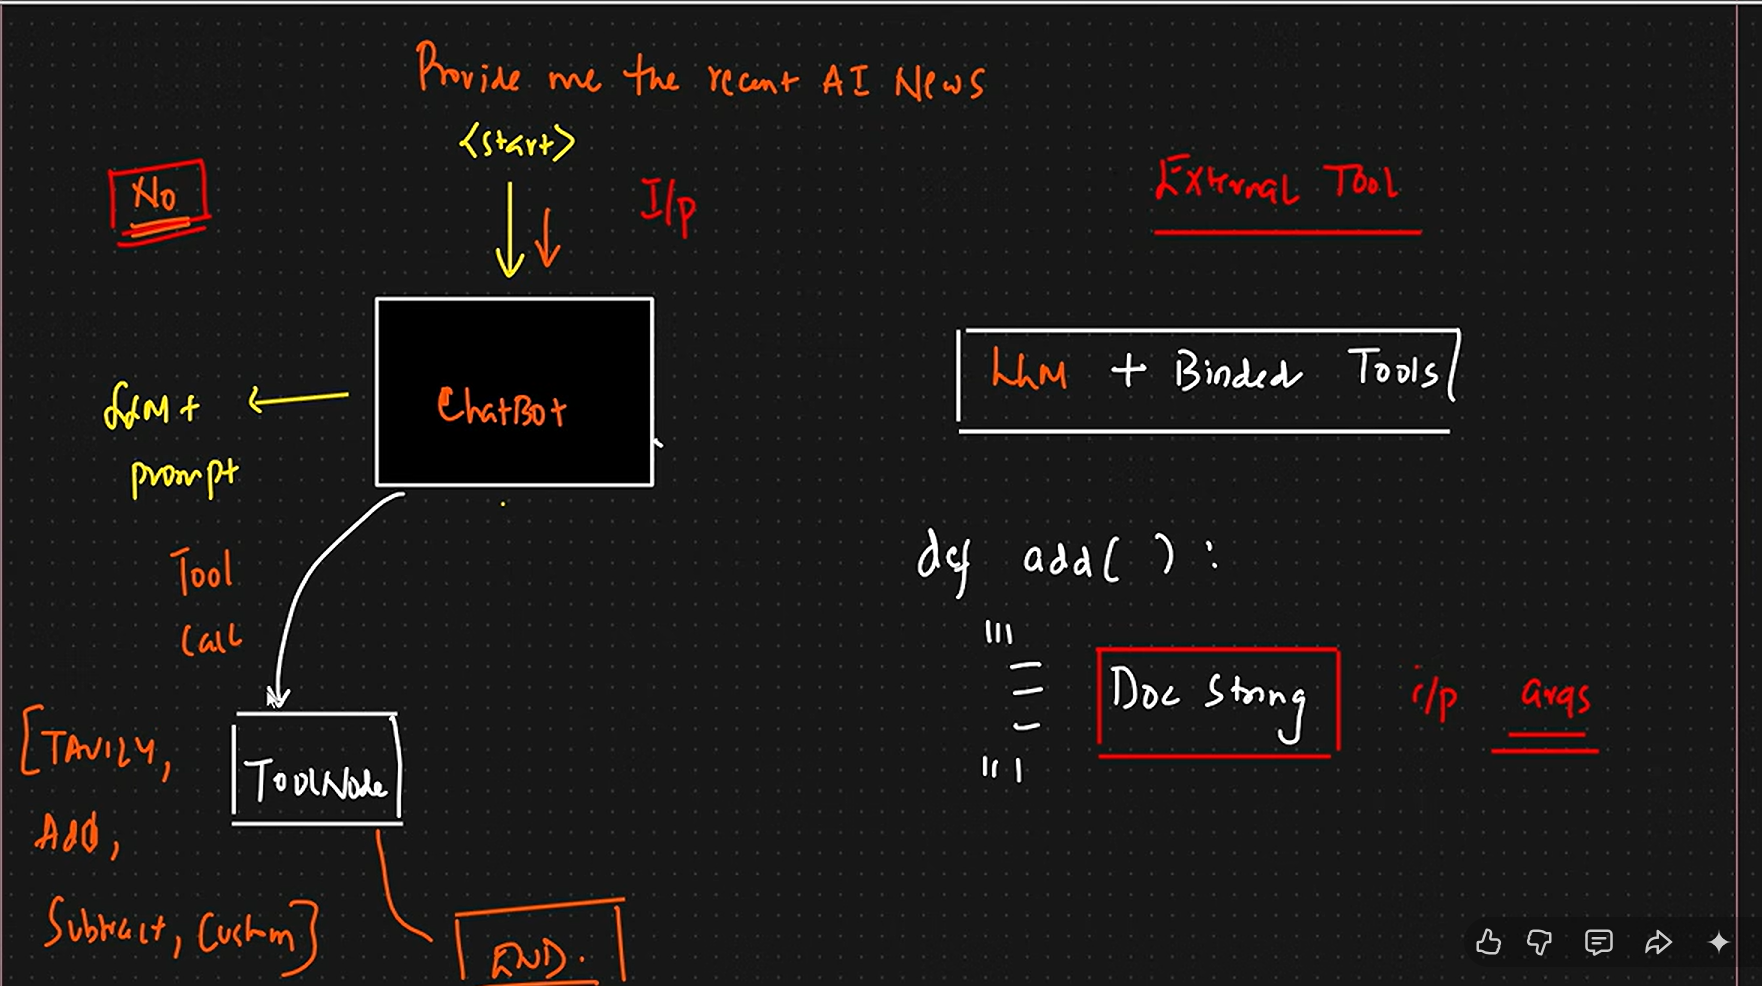

In [1]:
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain.chat_models import init_chat_model

load_dotenv(override=True)

class State(TypedDict):
    messages: Annotated[list, add_messages]

In [2]:
llm = init_chat_model("google_genai:gemini-3.5-flash-lite")

def chatbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}

In [3]:
graph_builder = StateGraph(State)

graph_builder.add_node("chatbot", chatbot)
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)

graph = graph_builder.compile()

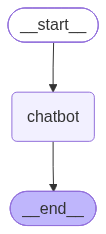

In [4]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print(graph.get_graph().draw_ascii())

In [5]:
# Single call using invoke()
response = graph.invoke({"messages": [("user", "Hello, how are you?")]})
print(response["messages"][-1].content)

[{'type': 'text', 'text': "Hello! I'm doing well, thank you for asking. How can I help you today?", 'extras': {'signature': 'EpYBCpMBAWkUfROvjds6vk/vX1Z8sW2fslr8yYjlIn3cRxLQ7wuua6jS8ks1Eqdzm41K5U6kTMi57ddd2HtoVlxLxY95TC8X0PRKVrzGnKp9A0zSb2OGy6pYJh64LadB+kENEs8e97FESCqFNlr7ah6Par8T4QltMtLwfT5yx6ZtU481ENMEO80/CfQiIfamxdne5viZABWM'}}]


In [6]:
# Streaming call using stream()
def stream_graph_updates(user_input: str):
    for event in graph.stream({"messages": [("user", user_input)]}):
        for value in event.values():
            print("Assistant:", value["messages"][-1].content)

stream_graph_updates("Explain LangGraph in one sentence.")

Assistant: [{'type': 'text', 'text': 'LangGraph is a library built on top of LangChain that allows developers to build stateful, multi-agent LLM applications by modeling agent workflows as graphs with nodes and edges.', 'extras': {'signature': 'EpYBCpMBAWkUfRNvzy1bl67x1NgJb8VR5HeBG4LMi7bf0ktD+n4gBqdiEm8UpvfGNlllL/81d6Q5alm3MNMYCyW6RPmFrh7HVc8HwJBAUvMI4FXMzeMitDcsHuVBHRM99ewVMY5BHajQ4R+jJMfo6QX+D1sRWy+pY0ZdmUHkA0yHtoHLJ5xZIMJP7xedi8A36fPY2hlAKRTR'}}]


Here is a simple breakdown of what we just built across those 5 chunks—your very first working **LangGraph Chatbot**:

### 1. Created the Shared Memory Box (`State`)

* In **Chunk 1**, we created a shared dictionary called `State` containing a single key: `messages`.
* By wrapping it with `Annotated[list, add_messages]`, we told LangGraph: *"Every time a step returns a new message, **append** it to the conversation history instead of erasing the old messages."*

### 2. Created the AI Worker (`chatbot` Node)

* In **Chunk 2**, we loaded your **Gemini** model (`init_chat_model`) and placed it inside a normal Python function called `chatbot(state)`.
* Whenever this node runs, it reads all messages stored in `state["messages"]`, sends them to Gemini, and hands Gemini's reply back to `State`.

### 3. Connected the Flowchart (`StateGraph` + Edges)

* In **Chunk 3**, we wired the steps together using `StateGraph`:
* **`START` $\rightarrow$ `"chatbot"**` (send the user's message to the Gemini node)
* **`"chatbot"` $\rightarrow$ `END**` (once Gemini replies, finish the workflow)


* Calling `.compile()` locked this blueprint into a runnable program (`graph`).

### 4. Visualized & Ran the Workflow (`draw_mermaid_png`, `invoke`, `stream`)

* In **Chunk 4**, we drew the visual diagram (`START -> chatbot -> END`) so you can verify your flowchart structure.
* In **Chunk 5**, we ran the graph in two ways:
* **`graph.invoke(...)`**: Runs the whole flowchart and gives you the final reply all at once.
* **`graph.stream(...)`**: Yields updates step-by-step as each node finishes running.



Right now, this is a simple single-node flowchart (`START -> chatbot -> END`). Next in Krish's tutorial, he will add **Tools** and **Conditional Edges (`if/else`)** so the graph can decide whether to answer directly or loop through an external tool first.